# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


## Данные

In [2]:
files = ['0.xls', '1.xls', '2.xlsx', '3.xlsx', '4.xlsx', '5.xlsx']
manh = [False, False, False, True, True, False]

data = []
for f in files:
    t = pd.read_excel(f, header=None)
    t = t.apply(pd.to_numeric, errors='coerce').dropna()
    data.append(t.values)

for i in range(6):
    print(i, len(data[i]), 'точек')

0 100 точек
1 9999 точек
2 1000 точек
3 10000 точек
4 500 точек
5 9999 точек


## 1. Распределение точек

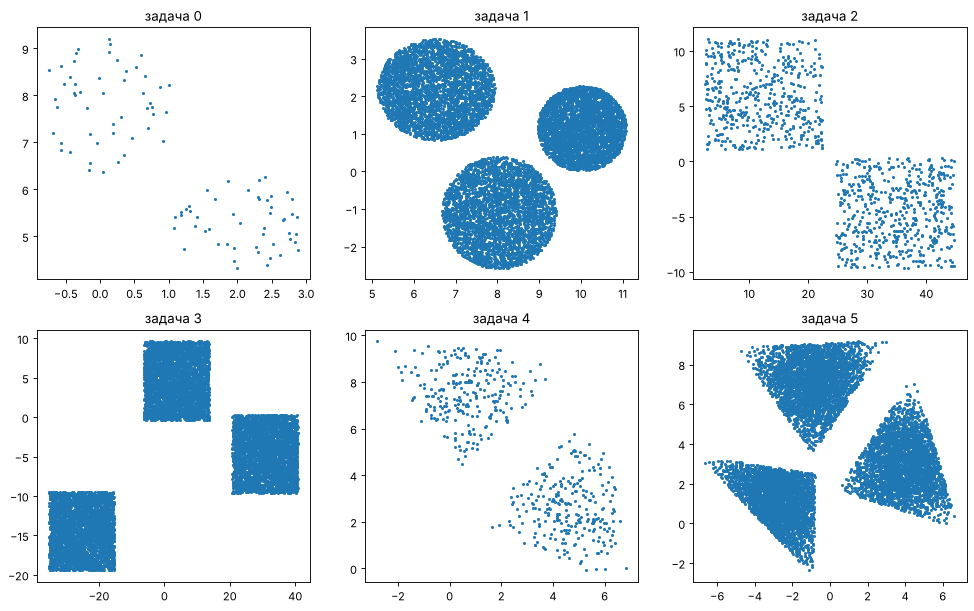

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for i in range(6):
    a = ax[i // 3][i % 3]
    a.scatter(data[i][:, 0], data[i][:, 1], s=3)
    a.set_title('задача ' + str(i))
plt.show()

## 2. Кластеризация руками

In [4]:
def nearest(pts, cent):
    res = []
    for x, y in pts:
        best = 0
        for k in range(len(cent)):
            d = (x - cent[k][0]) ** 2 + (y - cent[k][1]) ** 2
            d_best = (x - cent[best][0]) ** 2 + (y - cent[best][1]) ** 2
            if d < d_best:
                best = k
        res.append(best)
    return np.array(res)

labels = []

x = data[0][:, 0]; y = data[0][:, 1]
labels.append(np.where(y > 6.3, 0, 1))

labels.append(nearest(data[1], [[6.5, 2.2], [10, 1.2], [8, -1.1]]))

x = data[2][:, 0]
labels.append(np.where(x < 23.5, 0, 1))

x = data[3][:, 0]
labels.append(np.where(x < -10, 0, np.where(x > 15, 1, 2)))

x = data[4][:, 0]; y = data[4][:, 1]
labels.append(np.where(y - x > 3, 0, 1))

labels.append(nearest(data[5], [[-3, 0.7], [4, 2.6], [-1, 7]]))

for i in range(6):
    print(i, 'размеры кластеров:', np.bincount(labels[i]))

0 размеры кластеров: [50 50]
1 размеры кластеров: [3333 3333 3333]
2 размеры кластеров: [476 524]
3 размеры кластеров: [3429 3287 3284]
4 размеры кластеров: [250 250]
5 размеры кластеров: [3333 3333 3333]


## 3. Те же точки, но с цветами кластеров

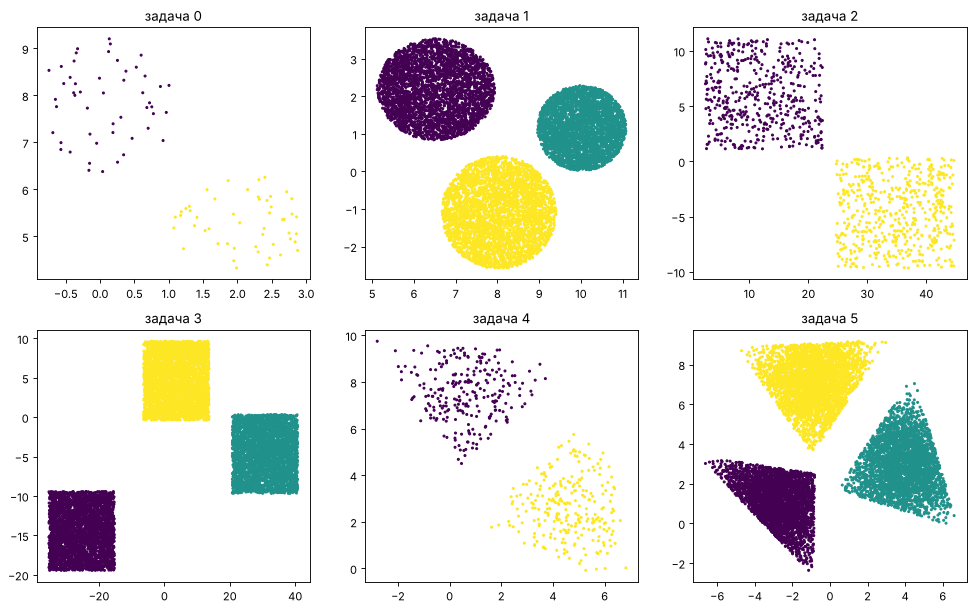

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for i in range(6):
    a = ax[i // 3][i % 3]
    a.scatter(data[i][:, 0], data[i][:, 1], c=labels[i], s=3)
    a.set_title('задача ' + str(i))
plt.show()

## 4. Центры кластеров

In [6]:
def dist(x1, y1, x2, y2, m):
    if m:
        return abs(x1 - x2) + abs(y1 - y2)
    return np.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

def find_center(pts, m):
    best = 1e18
    best_p = pts[0]
    for i in range(len(pts)):
        s = dist(pts[:, 0], pts[:, 1], pts[i, 0], pts[i, 1], m).sum()
        if s < best:
            best = s
            best_p = pts[i]
    return best_p

centers = []
for i in range(6):
    c = []
    for k in range(labels[i].max() + 1):
        c.append(find_center(data[i][labels[i] == k], manh[i]))
    centers.append(np.array(c))
    print('задача', i)
    print(centers[i])

задача 0
[[0.04811155 8.05305091]
 [2.033901   5.2892959 ]]
задача 1
[[ 6.46998257  2.169761  ]
 [10.02253531  1.1542006 ]
 [ 8.04007453 -1.10870557]]
задача 2
[[11.3340802   5.96596108]
 [34.92635132 -4.69527649]]
задача 3
[[-25.1307584  -14.41332836]
 [ 30.84952916  -4.51720291]
 [  3.51791128   4.65369556]]
задача 4
[[0.67779061 7.46832145]
 [4.49928923 2.52481355]]
задача 5
[[-2.74967383  1.14305932]
 [ 3.85858481  2.90716697]
 [-0.92395442  7.11986015]]


## 5. Среднее центров * 1000

In [7]:
for i in range(6):
    px = centers[i][:, 0].mean()
    py = centers[i][:, 1].mean()
    print('задача', i, ':', px * 1000, py * 1000)

задача 0 : 1041.0062778531646 6671.173406645906
задача 1 : 8177.530805155861 738.4186756580933
задача 2 : 23130.215759490402 635.3422943684297
задача 3 : 3078.8940144369562 -4758.945238436556
задача 4 : 2588.539921894905 4996.567503447351
задача 5 : 61.652188746546656 3723.362146439833


# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [8]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice

In [9]:
two_means = cluster.MiniBatchKMeans(n_clusters=3)
dbscan = cluster.DBSCAN(eps=0.3, min_samples=20)

clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

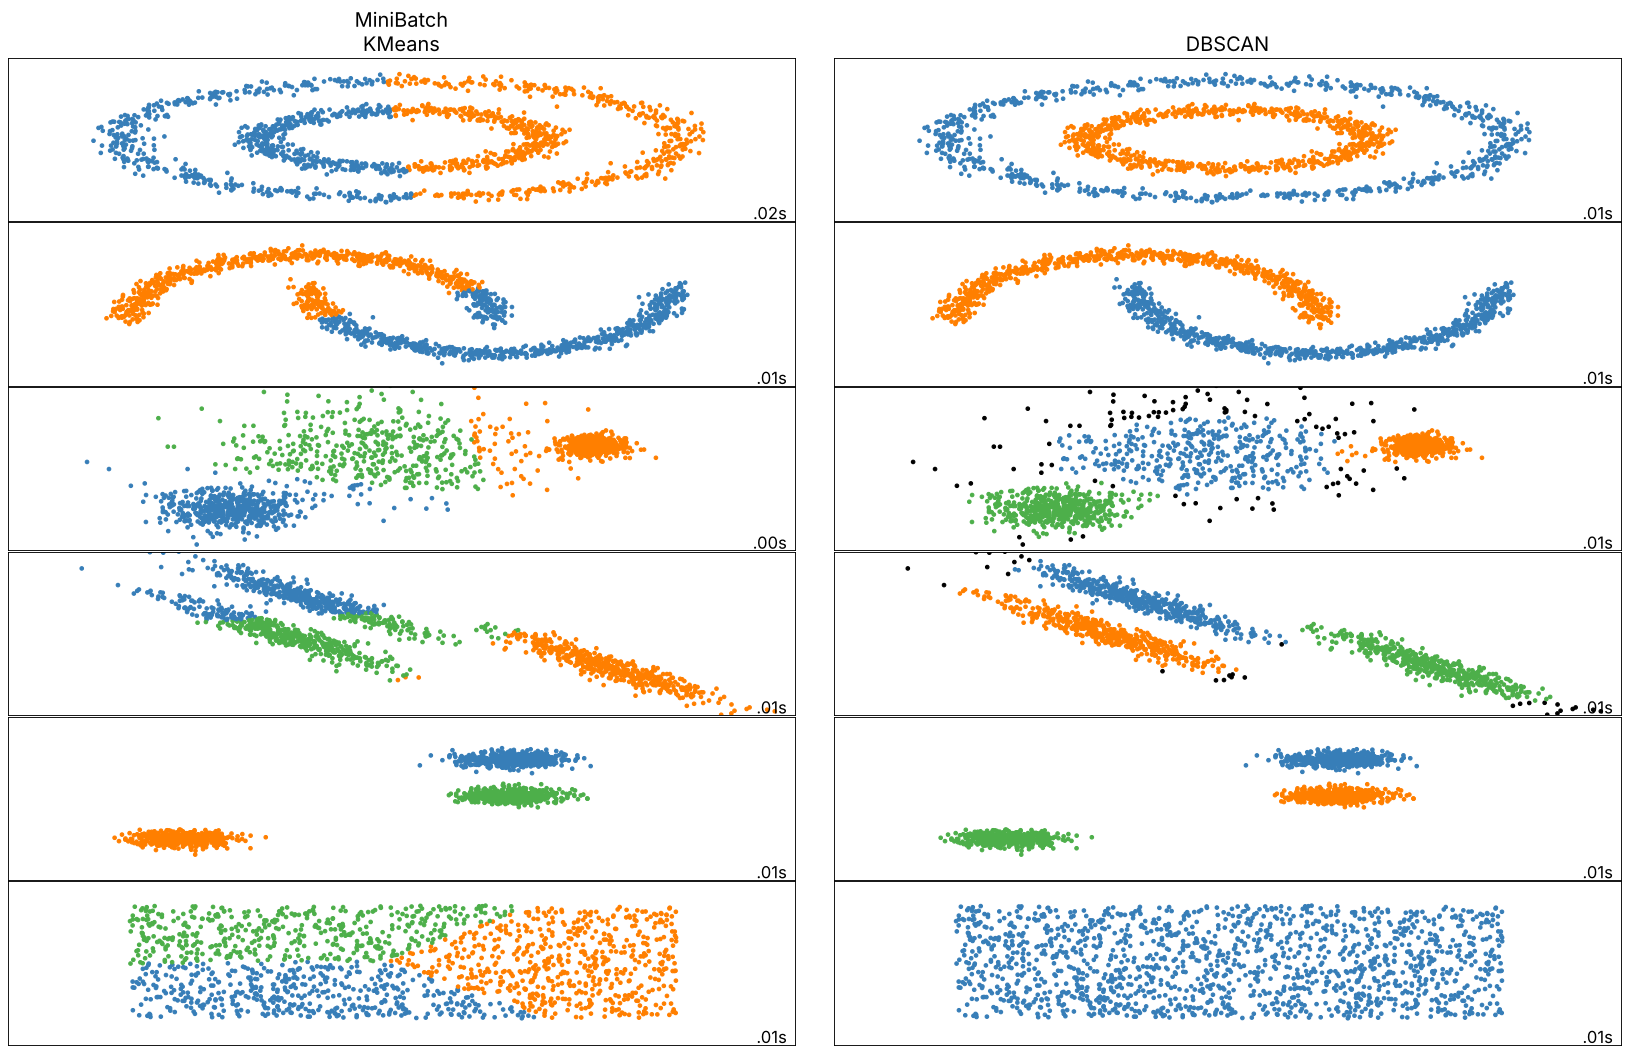

In [10]:
np.random.seed(0)

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(9 * 2 + 3, 13))
plt.subplots_adjust(
    left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 10,
    "n_clusters": 3,
    "min_samples": 20,
    "xi": 0.05,
    "min_cluster_size": 0.1,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 20,
            "xi": 0.25,
        },
    ),
    (noisy_moons, {"damping": 0.75, "preference": -220, "n_clusters": 2}),
    (
        varied,
        {
            "eps": 0.2,
            "n_neighbors": 2,
            "min_samples": 10,
            "xi": 0.035,
            "min_cluster_size": 0.2,
        },
    ),
    (
        aniso,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 10,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
    ),
    (blobs, {}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    two_means = cluster.MiniBatchKMeans(n_clusters=params["n_clusters"])
    dbscan = cluster.DBSCAN(eps=params["eps"], min_samples=params["min_samples"])
    clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

    for name, algorithm in clustering_algorithms:
        t0 = time.time()
        algorithm.fit(X)
        t1 = time.time()
        y_pred = algorithm.labels_.astype(int)

        plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)

        colors = np.array(list(islice(cycle(["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628",
                                              "#984ea3", "#999999", "#e41a1c", "#dede00"]),
                                      int(max(y_pred) + 1))))
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred])

        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        plt.text(0.99, 0.01, ("%.2fs" % (t1 - t0)).lstrip("0"),
                 transform=plt.gca().transAxes, size=15, horizontalalignment="right")
        plot_num += 1

plt.show()